In [4]:
import numpy as np
from typing import Tuple

def frozen_water(T: np.ndarray, wtot: np.ndarray, fp: float=2.0, To: float=0.0) -> Tuple:
    r""" 
    Approximates ice content from soil temperature and total water content.

    References:
        For peat soils, see experiment of Nagare et al. 2012:
        http://scholars.wlu.ca/cgi/viewcontent.cgi?article=1018&context=geog_faculty
    Args:
        T (array|float): soil temperature [degC]
        wtot (array|float): total volumetric water content [m3 m-3]
        fp (array|float): parameter of freezing curve [-]. 2...4 for clay and 0.5-1.5 for sandy soils; 
            < 0.5 for peat soils (Nagare et al. 2012 HESS)
        To (array|float): freezing temperature of soil water [degC]
    
    Returns:
        wliq (array|float): volumetric water content [m3 m-3]
        wice (array|float): volumetric ice content [m3 m-3]
        gamma (array|float): dwice/dT

    """

    wtot = np.array(wtot)
    T = np.array(T)
    fp = np.array(fp)

    wice = wtot*(1.0 - np.exp(-(To - T) / fp))
    # derivative dwliq/dT
    gamma = (wtot - wice) / fp

    ix = np.where(T > To)[0]
    wice[ix] = 0.0
    gamma[ix] = 0.0

    wliq = wtot - wice

    return wliq, wice, gamma

## Frozen water in peat

The freezing-curve parameter `fp` controls how quickly water becomes ice below `To`. The model documentation gives `fp < 0.5` for peat; smaller values produce a sharper transition just below the freezing point. The comparison below uses `fp=0.25` and `0.4` as illustrative peat cases, with `fp=1.0` as a sandy-soil reference. It holds total volumetric water content at `0.80 m3 m-3` to isolate the effect of `fp`; actual peat water content depends on site and state.

Total water content: 0.80 m3 m-3
Temperature [degC] | fp=0.10 ice | fp=0.50 ice | fp=1.00 ice | fp=3.00 ice
             -0.1 |       0.506 |       0.145 |       0.076 |       0.026
             -0.5 |       0.795 |       0.506 |       0.315 |       0.123
             -1.0 |       0.800 |       0.692 |       0.506 |       0.227


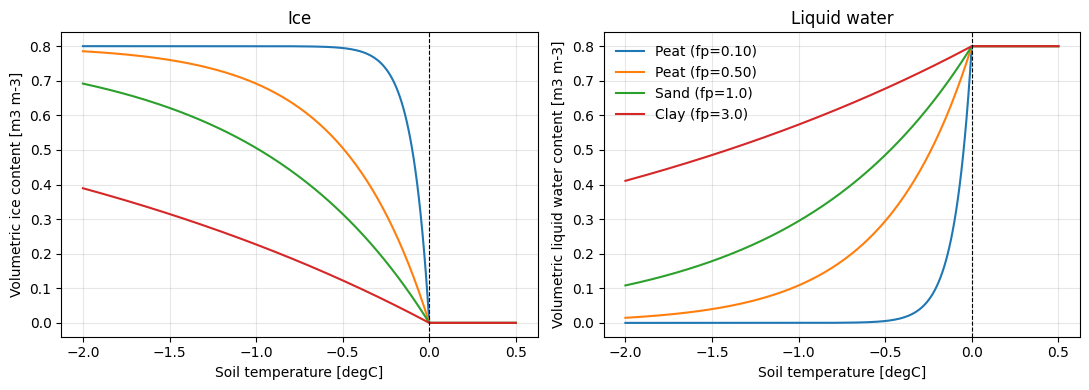

In [11]:
import matplotlib.pyplot as plt

To = 0.0
total_water = 0.80  # Illustrative wet-peat water content [m3 m-3]
temperature = np.linspace(-2.0, 0.5, 251)
freezing_parameters = {
    "Peat (fp=0.10)": 0.10,
    "Peat (fp=0.50)": 0.50,
    "Sand (fp=1.0)": 1.0,
    "Clay (fp=3.0)": 3.0,
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
for label, fp in freezing_parameters.items():
    liquid, ice, _ = frozen_water(temperature, total_water, fp=fp, To=To)
    axes[0].plot(temperature, ice, label=label)
    axes[1].plot(temperature, liquid, label=label)

for axis in axes:
    axis.axvline(To, color="black", linewidth=0.8, linestyle="--")
    axis.set_xlabel("Soil temperature [degC]")
    axis.grid(True, alpha=0.3)

axes[0].set_ylabel("Volumetric ice content [m3 m-3]")
axes[0].set_title("Ice")
axes[1].set_ylabel("Volumetric liquid water content [m3 m-3]")
axes[1].set_title("Liquid water")
axes[1].legend(frameon=False)
fig.tight_layout()

sample_temperatures = np.array([-0.1, -0.5, -1.0])
fp_values = (0.1, 0.5, 1.0, 3.0)
ice_by_fp = {
    fp: frozen_water(sample_temperatures, total_water, fp=fp, To=To)[1]
    for fp in fp_values
}
print(f"Total water content: {total_water:.2f} m3 m-3")
print("Temperature [degC] | fp=0.10 ice | fp=0.50 ice | fp=1.00 ice | fp=3.00 ice")
for index, value in enumerate(sample_temperatures):
    print(
        f"{value:>17.1f} | {ice_by_fp[0.1][index]:>11.3f} | "
        f"{ice_by_fp[0.5][index]:>11.3f} | {ice_by_fp[1.0][index]:>11.3f} | {ice_by_fp[3.0][index]:>11.3f}"
    )